In [2]:
import pandas as pd

df = pd.read_csv("../data/thessaloniki_hourly.csv")
print(df.columns.tolist())

['time', 'pm10', 'pm2_5', 'nitrogen_dioxide', 'ozone', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'wind_direction_10m', 'surface_pressure', 'precipitation']


In [3]:
df["time"] = pd.to_datetime(df["time"])
print(df.shape)
print(df["time"].min(), "to", df["time"].max())
print(df.isna().sum())
df.head()

(61368, 11)
2019-01-01 00:00:00 to 2025-12-31 23:00:00
time                        0
pm10                        0
pm2_5                       0
nitrogen_dioxide            0
ozone                       0
temperature_2m          61368
relative_humidity_2m    61368
wind_speed_10m          61368
wind_direction_10m      61368
surface_pressure        61368
precipitation           61368
dtype: int64


,time,pm10,pm2_5,nitrogen_dioxide,ozone,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,surface_pressure,precipitation
0,2019-01-01 00:00:00,17.9,11.6,11.4,37.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-01-01 01:00:00,17.6,12.0,10.2,44.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2019-01-01 02:00:00,15.6,16.1,6.4,56.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-01-01 03:00:00,16.1,16.1,10.3,51.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-01-01 04:00:00,17.7,16.7,13.6,48.0,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df[df["temperature_2m"].isna()]["time"].agg(["min", "max", "count"]))

min      2019-01-01 00:00:00
max      2025-12-31 23:00:00
count                  61368
Name: time, dtype: object


In [5]:
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
for lat, lon, model in [(40.64, 22.94, None), (40.64, 22.94, "era5"), (40.63, 22.96, None)]:
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": "2019-01-01", "end_date": "2019-01-02",
        "hourly": "temperature_2m", "timezone": "Europe/Athens",
    }
    if model:
        params["models"] = model
    r = requests.get(url, params=params, timeout=60)
    temps = r.json().get("hourly", {}).get("temperature_2m", [])[:5]
    print(lat, lon, model, "->", temps)

40.64 22.94 None -> [4.8, 4.4, 4.5, 4.8, 4.3]
40.64 22.94 era5 -> [5.8, 6.2, 6.0, 5.5, 4.9]
40.63 22.96 None -> [4.1, 3.7, 3.9, 4.2, 3.7]


In [6]:
import time

weather_vars = [
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "wind_direction_10m", "surface_pressure", "precipitation",
]

frames = []
for year in range(2019, 2026):
    params = {
        "latitude": 40.64, "longitude": 22.94,
        "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
        "hourly": ",".join(weather_vars), "timezone": "Europe/Athens",
    }
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
    w = pd.DataFrame(r.json()["hourly"])
    print(year, len(w), "rows,", w["temperature_2m"].isna().sum(), "missing temperatures")
    frames.append(w)
    time.sleep(1)

weather = pd.concat(frames, ignore_index=True)
weather["time"] = pd.to_datetime(weather["time"])

2019 8760 rows, 0 missing temperatures
2020 8784 rows, 0 missing temperatures
2021 8760 rows, 0 missing temperatures
2022 8760 rows, 0 missing temperatures
2023 8760 rows, 0 missing temperatures
2024 8784 rows, 0 missing temperatures
2025 8760 rows, 0 missing temperatures


In [7]:
air = df[["time", "pm10", "pm2_5", "nitrogen_dioxide", "ozone"]]
df = air.merge(weather, on="time", how="inner")

print(df.shape)
print(df.isna().sum())
df.to_csv("../data/thessaloniki_hourly.csv", index=False)


(61368, 11)
time                    0
pm10                    0
pm2_5                   0
nitrogen_dioxide        0
ozone                   0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
wind_direction_10m      0
surface_pressure        0
precipitation           0
dtype: int64


(2556, 10)
count    2556.0
mean       13.9
std         5.9
min         2.9
25%         9.7
50%        12.6
75%        16.8
max        40.9
Name: pm2_5, dtype: float64


<Axes: title={'center': 'Daily average PM2.5, Thessaloniki (CAMS model)'}, xlabel='time'>

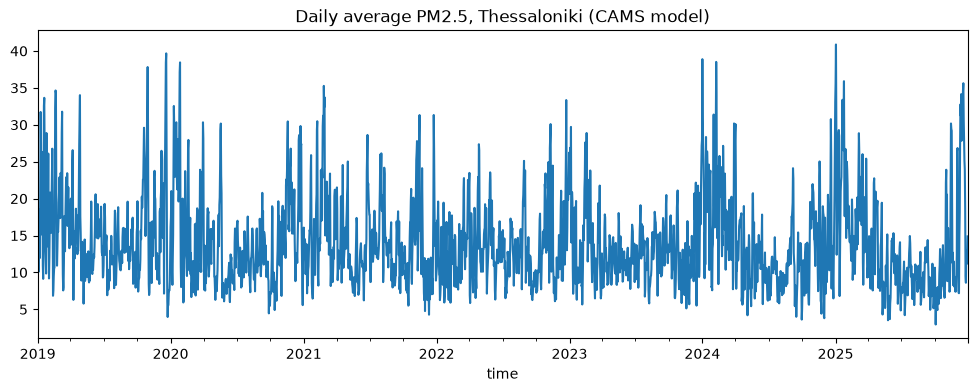

In [8]:
daily = (
    df.set_index("time")
    .resample("D")
    .agg({
        "pm10": "mean", "pm2_5": "mean", "nitrogen_dioxide": "mean", "ozone": "mean",
        "temperature_2m": "mean", "relative_humidity_2m": "mean",
        "wind_speed_10m": "mean", "surface_pressure": "mean",
        "precipitation": "sum",
    })
)

# Target: tomorrow's average PM2.5
daily["pm2_5_tomorrow"] = daily["pm2_5"].shift(-1)
daily = daily.dropna()

print(daily.shape)
print(daily["pm2_5"].describe().round(1))

daily["pm2_5"].plot(figsize=(12, 4), title="Daily average PM2.5, Thessaloniki (CAMS model)")

In [9]:
import numpy as np

# Wind direction done properly: turn each hour's wind into east-west (u) and north-south (v) parts, then average
rad = np.radians(df["wind_direction_10m"])
df["wind_u"] = -df["wind_speed_10m"] * np.sin(rad)
df["wind_v"] = -df["wind_speed_10m"] * np.cos(rad)
wind = df.set_index("time")[["wind_u", "wind_v"]].resample("D").mean()
daily = daily.join(wind)

# Pollution history
daily["pm2_5_lag1"] = daily["pm2_5"].shift(1)                   # yesterday
daily["pm2_5_mean3"] = daily["pm2_5"].rolling(3).mean()         # last 3 days

# Season and weekday
doy = daily.index.dayofyear
daily["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
daily["season_cos"] = np.cos(2 * np.pi * doy / 365.25)
daily["weekday"] = daily.index.dayofweek

daily = daily.dropna()
print(daily.shape)

(2554, 17)


C:\Users\Christos\AppData\Local\Temp\ipykernel_1456\3241547569.py:15: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  doy = daily.index.dayofyear
C:\Users\Christos\AppData\Local\Temp\ipykernel_1456\3241547569.py:18: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily["weekday"] = daily.index.dayofweek


In [10]:
from sklearn.metrics import mean_absolute_error

target = "pm2_5_tomorrow"
feature_cols = [c for c in daily.columns if c != target]

train = daily[daily.index < "2024-01-01"]
test = daily[daily.index >= "2024-01-01"]
X_train, y_train = train[feature_cols], train[target]
X_test, y_test = test[feature_cols], test[target]
print(len(train), "training days,", len(test), "test days")

# Baseline 1: tomorrow will be the same as today (persistence)
mae_persist = mean_absolute_error(y_test, X_test["pm2_5"])
# Baseline 2: tomorrow will be the training average
mae_mean = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

print(f"Persistence baseline: MAE {mae_persist:.2f} µg/m³")
print(f"Mean baseline:        MAE {mae_mean:.2f} µg/m³")

1824 training days, 730 test days
Persistence baseline: MAE 2.97 µg/m³
Mean baseline:        MAE 5.34 µg/m³
